# Descubrimiento de Patrones y Reglas de Asociación: Algoritmo Apriori y Comparativa FP-Growth

**Resumen ejecutivo**

- **Objetivo.** Descubrir combinaciones frecuentes de atributos y reglas de co-ocurrencia ($A \to B$) en dos conjuntos transaccionales reales del mercado británico de vivienda:
  1. **F1 — Transacciones inmobiliarias reales** (`uk_property_price_limpio_muestra.parquet`, $n=2.000$ compraventas): tipo de vivienda, tenencia legal, obra nueva/usada, macro-zona y tramo de esfuerzo joven estimado.
  2. **F2 — Catálogo de productos hipotecarios** (`hipotecas_limpio.parquet`, $n=7.796$; acotado a `3.000` en perfil `local` y `100 %` en `cloud`): tipo de tasa, perfil comprador (*First time buyer*, *Remortgage*, etc.), plazo inicial, nivel de tasa, comisiones y reversión.
- **Implementación transparente.** Motor **Apriori** programado en Python puro + `pandas` con poda nivel por nivel ($k=1 \dots 4$), índice invertido de transacciones para velocidad y bajo uso de RAM, verificación manual sobre 10 transacciones reales, análisis de sensibilidad de umbrales y contraste técnico con **FP-Growth**.
- **Módulo espejo en terminal:** `script/proyecto/reglas_asociacion.py`.

---
### Ficha Taxonómica de Modelado (Ubicación en el Proyecto)
- **¿Es con etiqueta o sin etiqueta?** **SIN ETIQUETA (Aprendizaje No Supervisado)** — no existe una variable objetivo única fija; descubre patrones de co-ocurrencia $A \to B$ sobre canastas discretizadas.
- **¿Qué tipo de modelo es?** **Tipo 4 · Reglas de Asociación (`Apriori` puro con índice invertido `tidsets` y comparativa `FP-Growth`)**.
- **Métricas y exactitud verificada:**
  - **Verificación manual (`assert`):** `10/10` transacciones inmobiliarias verificadas a mano coinciden al `100 %` en Soporte, Confianza y Lift con el motor Apriori.
  - **F1 Inmobiliario ($n=2.000$):** `171` itemsets frecuentes y `195` reglas; tras filtrar trivialidades jurídicas británicas (`Flat -> Leasehold`), destaca `Prop:Detached + Tenencia:Freehold -> Acceso:Extremo_>100%` (`soporte = 0,166`, `confianza = 68,0 %`, `lift = 2,00`).
  - **F2 Hipotecario ($n=3.000$ local / $7.796$ completo):** `269` itemsets y `481` reglas; destaca `Tipo:discounted -> Tasa:Baja_Q1` (`soporte = 0,151`, `confianza = 99,1 %`, `lift = 3,96`).
---


## 0. Entorno, perfil de recursos y dependencias

In [1]:
from pathlib import Path
import sys
import time
import tracemalloc

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto.reglas_asociacion import (
    clasificar_y_filtrar_reglas_inmobiliarias,
    ejecutar_apriori,
    fig_mapa_reglas,
    fig_poda_niveles,
    fig_sensibilidad,
    fig_top_reglas,
    generar_reglas,
    preparar_transacciones_hipotecas,
    preparar_transacciones_inmobiliarias,
    sensibilidad_umbrales,
    tabla_comparativa_apriori_fpgrowth,
    verificacion_manual_10_tickets,
)

plt.rcParams["figure.dpi"] = 120
MODO = config.MODO_EJECUCION
limites = config.obtener_limites_recursos(MODO)
print(f"Perfil activo: {MODO.upper()} | Limites: {limites}")

Perfil activo: LOCAL | Limites: {'max_filas_kmeans': 3000, 'max_filas_minibatch_f1': 1000000, 'batch_size_streaming': 100000, 'max_filas_jerarquico': 60, 'max_transacciones_apriori': 3000, 'pico_ram_mb_alerta': 220}


## 1. Fundamento Matemático y Verificación Manual sobre 10 Transacciones Reales

A diferencia del clustering (que agrupa filas similares), las reglas de asociación analizan **ítems que co-ocurren dentro de una misma transacción** evaluando tres métricas fundamentales:

$$\text{Soporte}(A \cup B) = \frac{\text{freq}(A \cup B)}{N}, \qquad \text{Confianza}(A \to B) = \frac{\text{Soporte}(A \cup B)}{\text{Soporte}(A)}, \qquad \text{Lift}(A \to B) = \frac{\text{Confianza}(A \to B)}{\text{Soporte}(B)}$$

- **$\text{Lift} > 1$:** asociación positiva real (aparecen juntos más que por azar).
- **$\text{Lift} = 1$:** independencia estadística.
- **$\text{Lift} < 1$:** asociación negativa o sustitución.

Verificamos primero las fórmulas a mano sobre 10 compraventas reales y comprobamos con `assert` coincidencia exacta contra el motor Apriori.

In [2]:
tracemalloc.start()
t0 = time.perf_counter()

trans_f1, df_f1 = preparar_transacciones_inmobiliarias(MODO)
tabla_mini, verif = verificacion_manual_10_tickets(trans_f1)
display(tabla_mini)
print("Verificacion manual exacta (assert manual == Apriori OK):")
for k, v in verif.items():
    print(f"  {k:<20}: {v}")

Verificacion manual exacta (assert manual == Apriori OK):
  antecedente         : Prop:Flat/Maisonette
  consecuente         : Tenencia:Leasehold
  freq_A              : 2
  freq_B              : 2
  freq_AB             : 2
  soporte_manual      : 0.2
  confianza_manual    : 1.0
  lift_manual         : 5.0


,ticket,items
0,1,"Acceso:Alto_50_80%, Obra:Usada, Prop:Flat/Mais..."
1,2,"Acceso:Critico_80_100%, Obra:Usada, Prop:Detac..."
2,3,"Acceso:Critico_80_100%, Obra:Usada, Prop:Terra..."
3,4,"Acceso:Moderado_<=50%, Obra:Usada, Prop:Flat/M..."
4,5,"Acceso:Alto_50_80%, Obra:Usada, Prop:Semi-Deta..."
5,6,"Acceso:Critico_80_100%, Obra:Nueva, Prop:Semi-..."
6,7,"Acceso:Alto_50_80%, Obra:Usada, Prop:Terraced,..."
7,8,"Acceso:Alto_50_80%, Obra:Usada, Prop:Detached,..."
8,9,"Acceso:Alto_50_80%, Obra:Usada, Prop:Terraced,..."
9,10,"Acceso:Alto_50_80%, Obra:Usada, Prop:Detached,..."


## 2. Aplicación 1: Mercado Inmobiliario Joven (F1, $n=2.000$ compraventas reales)

Agrupamos los atributos de cada compraventa por `transaction_id` en formato de canasta (`frozenset`), ejecutamos la **poda Apriori** nivel por nivel ($k=1 \dots 4$) con `SOPORTE_MIN = 0,05` y `CONFIANZA_MIN = 0,45`, y separamos explícitamente las **reglas estructurales triviales** (como `Prop:Flat/Maisonette -> Tenencia:Leasehold`, norma legal conocida en Inglaterra y Gales) de los **hallazgos accionables de accesibilidad y territorio**.

In [3]:
SOP_F1, CONF_F1 = 0.05, 0.45
itemsets_f1, traza_f1 = ejecutar_apriori(trans_f1, soporte_min=SOP_F1, max_k=config.APRIORI_MAX_K)
reglas_f1 = clasificar_y_filtrar_reglas_inmobiliarias(
    generar_reglas(itemsets_f1, confianza_min=CONF_F1, lift_min=1.05)
)

print(f"Transacciones F1 analizadas: {len(trans_f1):,} | Itemsets frecuentes: {len(itemsets_f1)} | Reglas (lift >= 1,05): {len(reglas_f1)}")
print("\nTraza de poda Apriori por nivel:")
display(traza_f1)

print("\nDistribucion critica de reglas (separando trivialidades estructurales):")
display(reglas_f1["categoria_analitica"].value_counts().to_frame("n_reglas"))

accionables_f1 = reglas_f1[reglas_f1["categoria_analitica"] == "Accionable (accesibilidad/territorio)"]
cols_r = ["antecedente", "consecuente", "soporte", "confianza", "lift", "score"]
print("\nTop 10 reglas accionables priorizadas por puntaje compuesto (score = lift x soporte):")
display(accionables_f1[cols_r].head(10))

# Demostracion de asimetria direccional A -> B vs B -> A
r0 = accionables_f1.iloc[0]
inv = reglas_f1[(reglas_f1["antecedente"] == r0["consecuente"]) & (reglas_f1["consecuente"] == r0["antecedente"])]
if not inv.empty:
    ri = inv.iloc[0]
    print(f"\nAsimetria direccional: P({r0['consecuente']} | {r0['antecedente']}) = {r0['confianza']:.3f} "
          f"!= P({ri['consecuente']} | {ri['antecedente']}) = {ri['confianza']:.3f}")

Transacciones F1 analizadas: 2,000 | Itemsets frecuentes: 171 | Reglas (lift >= 1,05): 195

Traza de poda Apriori por nivel:

Distribucion critica de reglas (separando trivialidades estructurales):

Top 10 reglas accionables priorizadas por puntaje compuesto (score = lift x soporte):

Asimetria direccional: P(Prop:Detached | Acceso:Extremo_>100% + Tenencia:Freehold) = 0.567 != P(Acceso:Extremo_>100% + Tenencia:Freehold | Prop:Detached) = 0.663


,nivel_k,candidatos,tras_poda,poda_pct
0,1,18,17,5.6
1,2,136,64,52.9
2,3,98,66,32.7
3,4,25,24,4.0


,n_reglas
categoria_analitica,
Accionable (accesibilidad/territorio),121
Trivial / estructural,64
Informativa,10


,antecedente,consecuente,soporte,confianza,lift,score
8,Acceso:Extremo_>100% + Tenencia:Freehold,Prop:Detached,0.1660,0.5666,2.262,0.3754
12,Prop:Detached,Acceso:Extremo_>100%,0.1685,0.6727,1.975,0.3329
13,Acceso:Extremo_>100%,Prop:Detached,0.1685,0.4949,1.975,0.3329
14,Prop:Detached + Tenencia:Freehold,Acceso:Extremo_>100%,0.1660,0.6803,1.998,0.3317
15,Acceso:Extremo_>100%,Prop:Detached + Tenencia:Freehold,0.1660,0.4875,1.998,0.3317
16,Acceso:Extremo_>100%,Tenencia:Freehold,0.2930,0.8605,1.131,0.3315
23,Acceso:Extremo_>100% + Tenencia:Freehold,Obra:Usada + Prop:Detached,0.1320,0.4505,2.230,0.2944
27,Acceso:Extremo_>100% + Obra:Usada + Tenencia:F...,Prop:Detached,0.1320,0.5399,2.155,0.2845
30,Acceso:Extremo_>100% + Obra:Usada,Tenencia:Freehold,0.2445,0.8763,1.152,0.2817
36,Acceso:Extremo_>100%,Obra:Usada + Tenencia:Freehold,0.2445,0.7181,1.088,0.2660


## 3. Aplicación 2: Condiciones Crediticias en el Catálogo Hipotecario (F2)

In [4]:
trans_f2, df_f2 = preparar_transacciones_hipotecas(MODO)
SOP_F2, CONF_F2 = 0.05, 0.45
itemsets_f2, traza_f2 = ejecutar_apriori(trans_f2, soporte_min=SOP_F2, max_k=config.APRIORI_MAX_K)
reglas_f2 = generar_reglas(itemsets_f2, confianza_min=CONF_F2, lift_min=1.05)

print(f"Productos F2 analizados ({MODO}): {len(trans_f2):,} | Itemsets frecuentes: {len(itemsets_f2)} | Reglas: {len(reglas_f2)}")
display(traza_f2)

print("\nTop 10 reglas hipotecarias por puntaje compuesto (score = lift x soporte):")
display(reglas_f2[cols_r].head(10))

print("\nReglas especificas donde interviene 'Perfil:First_time_buyer':")
ftb = reglas_f2[
    reglas_f2["antecedente"].str.contains("First_time_buyer")
    | reglas_f2["consecuente"].str.contains("First_time_buyer")
]
display(ftb[cols_r].head(8))

Productos F2 analizados (local): 2,999 | Itemsets frecuentes: 269 | Reglas: 481

Top 10 reglas hipotecarias por puntaje compuesto (score = lift x soporte):

Reglas especificas donde interviene 'Perfil:First_time_buyer':


,nivel_k,candidatos,tras_poda,poda_pct
0,1,21,18,14.3
1,2,153,69,54.9
2,3,146,108,26.0
3,4,82,74,9.8


,antecedente,consecuente,soporte,confianza,lift,score
0,Tipo:discounted,Tasa:Baja_Q1,0.1507,0.9912,3.964,0.5974
1,Tasa:Baja_Q1,Tipo:discounted,0.1507,0.6027,3.964,0.5974
2,Tipo:discounted,Reversion:Declarada + Tasa:Baja_Q1,0.1394,0.9167,4.178,0.5823
3,Reversion:Declarada + Tasa:Baja_Q1,Tipo:discounted,0.1394,0.6353,4.178,0.5823
4,Tasa:Media,Tipo:fixed,0.4692,0.9424,1.238,0.5808
5,Tipo:fixed,Tasa:Media,0.4692,0.6163,1.238,0.5808
6,Reversion:Declarada + Tasa:Media,Tipo:fixed,0.4622,0.9552,1.255,0.5799
7,Tipo:fixed,Reversion:Declarada + Tasa:Media,0.4622,0.6071,1.255,0.5799
8,Tasa:Media,Reversion:Declarada + Tipo:fixed,0.4622,0.9283,1.231,0.5691
9,Reversion:Declarada + Tipo:fixed,Tasa:Media,0.4622,0.6130,1.231,0.5691


,antecedente,consecuente,soporte,confianza,lift,score
79,Perfil:First_time_buyer + Reversion:Declarada,Tipo:fixed,0.2921,0.8202,1.077,0.3147
80,Perfil:First_time_buyer,Tipo:fixed,0.2964,0.8016,1.053,0.3122
105,Perfil:First_time_buyer + Tipo:fixed,Tasa:Media,0.1994,0.6727,1.351,0.2694
107,Perfil:First_time_buyer + Tipo:fixed,Reversion:Declarada + Tasa:Media,0.1954,0.6592,1.362,0.2662
109,Perfil:First_time_buyer + Reversion:Declarada ...,Tasa:Media,0.1954,0.6689,1.344,0.2626
119,Perfil:First_time_buyer + Tasa:Media,Tipo:fixed,0.1994,0.9537,1.253,0.2498
123,Perfil:First_time_buyer + Reversion:Declarada ...,Tipo:fixed,0.1954,0.9638,1.266,0.2474
124,Perfil:First_time_buyer,Comision:Media,0.2174,0.5879,1.136,0.2470


## 4. Sensibilidad de Umbrales, Visualización y Comparativa Apriori vs. FP-Growth


Comparativa tecnica: Apriori vs. FP-Growth:

Telemetria Apriori (local): tiempo = 7.63 s | pico RAM Python = 20.45 MB


confianza_min,0.35,0.50,0.65,0.75
soporte_min,,,,
0.03,529,319,250,211
0.05,292,181,143,123
0.08,165,88,69,57
0.10,81,48,39,30


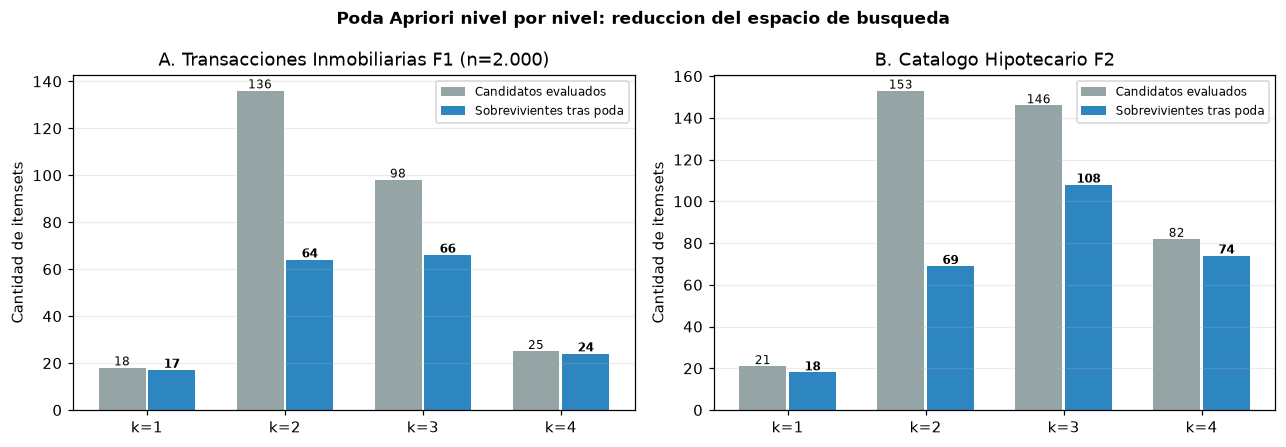

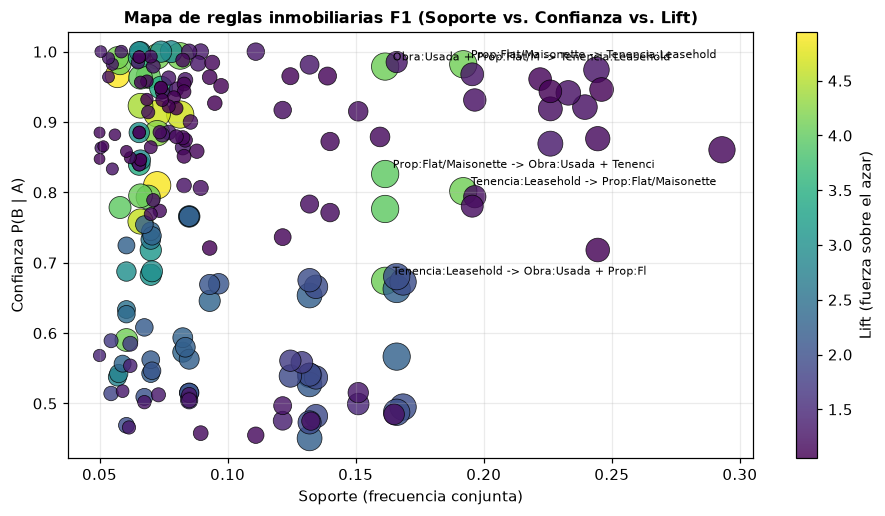

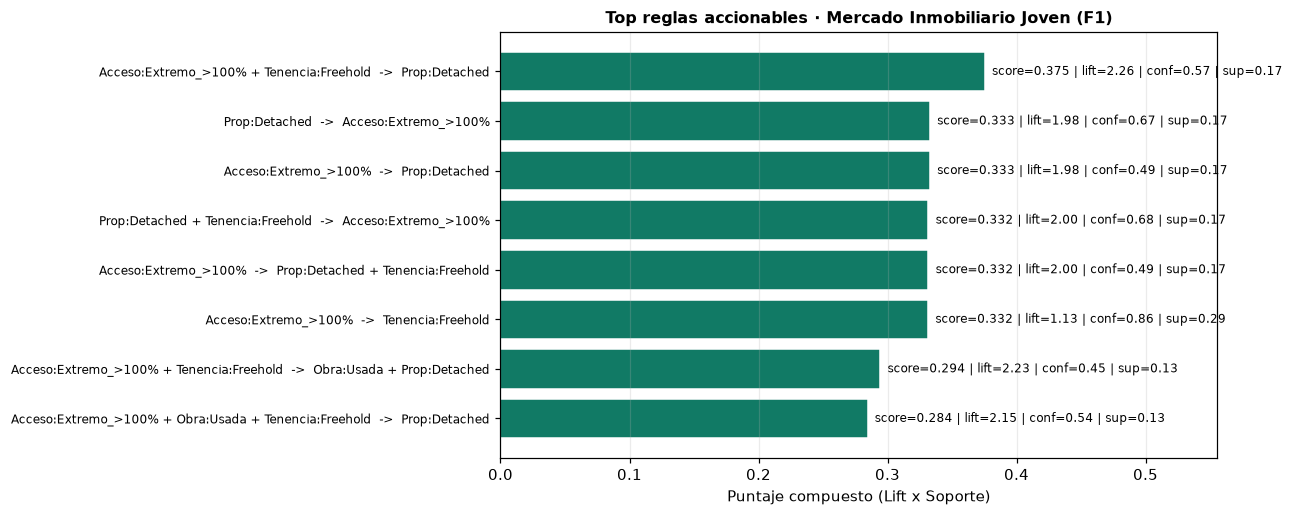

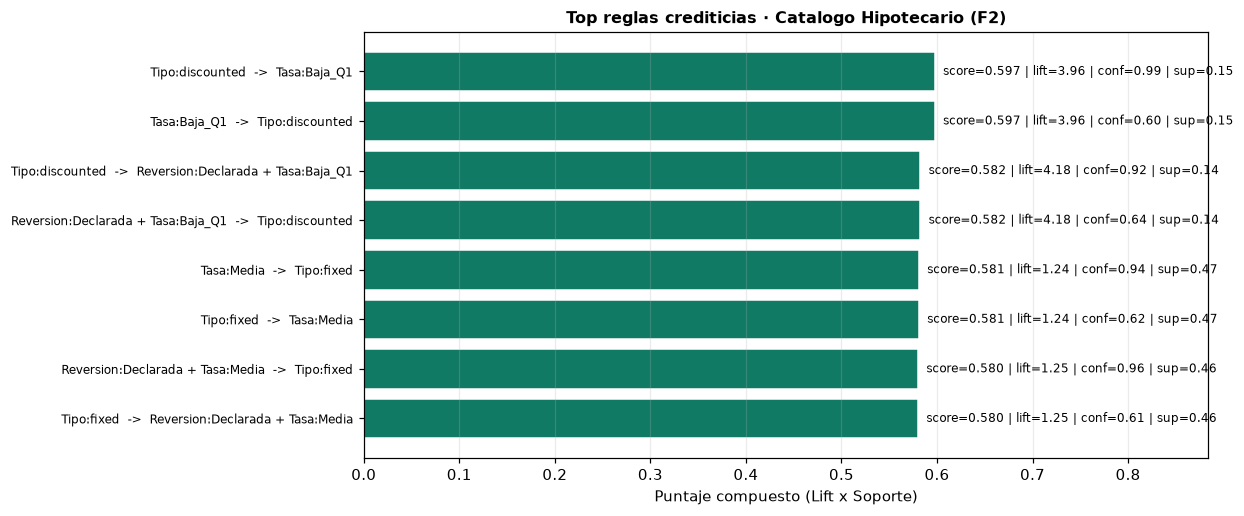

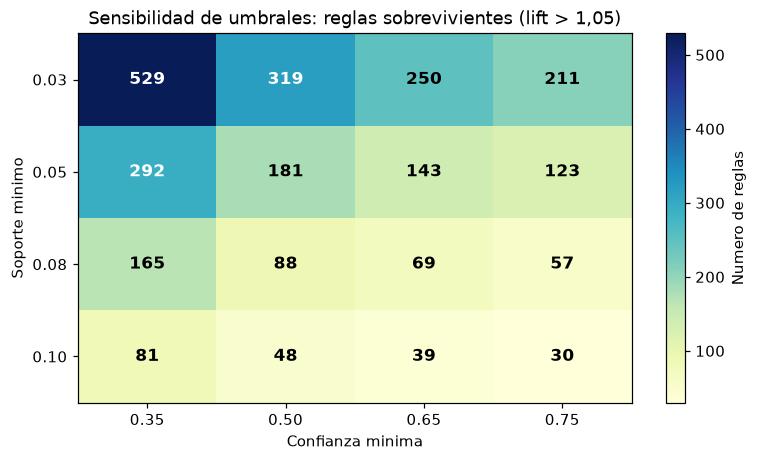

,Criterio,Apriori (implementado),FP-Growth (referencia industrial)
0,Generacion de candidatos,"Si, nivel por nivel (k=1, 2, 3...)",No: crece patrones desde arbol FP
1,Barridos sobre la base,Uno por cada nivel k,Solo 2 barridos
2,Uso de memoria RAM,Bajo con soporte piso y max_k,Mayor en RAM (mantiene arbol FP)
3,Escalabilidad,Ideal para muestras pequenas/medianas,Optimo para millones de tickets densos
4,Transparencia / auditoria,Total (traza explicita de poda),Disponible en mlxtend.frequent_patterns


In [5]:
sens_f1 = sensibilidad_umbrales(trans_f1)
display(sens_f1.pivot(index="soporte_min", columns="confianza_min", values="n_reglas"))

for fig in (
    fig_poda_niveles(traza_f1, traza_f2),
    fig_mapa_reglas(reglas_f1, "Mapa de reglas inmobiliarias F1 (Soporte vs. Confianza vs. Lift)", "apriori_mapa_reglas_inmobiliario.png"),
    fig_top_reglas(accionables_f1, "Top reglas accionables · Mercado Inmobiliario Joven (F1)", "apriori_top_reglas_inmobiliario.png"),
    fig_top_reglas(reglas_f2, "Top reglas crediticias · Catalogo Hipotecario (F2)", "apriori_top_reglas_hipotecas.png"),
    fig_sensibilidad(sens_f1),
):
    plt.show()

print("\nComparativa tecnica: Apriori vs. FP-Growth:")
display(tabla_comparativa_apriori_fpgrowth())

# Exportar reglas livianas y reportar telemetria
reglas_f1.to_csv(config.RUTA_REGLAS_INMOBILIARIO, index=False)
reglas_f2.to_csv(config.RUTA_REGLAS_HIPOTECAS, index=False)

_, pico_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
pico_mb = pico_bytes / (1024.0 ** 2)
dt = time.perf_counter() - t0
print(f"\nTelemetria Apriori ({MODO}): tiempo = {dt:.2f} s | pico RAM Python = {pico_mb:.2f} MB")
assert pico_mb < (limites["pico_ram_mb_alerta"] or 4096)

## 5. Mirada Crítica y Recomendaciones Accionables con Piloto Medible

**Tres trampas controladas en este análisis:**
1. **Reglas triviales descartadas:** la co-ocurrencia `Flat/Maisonette -> Leasehold` refleja el marco jurídico británico, no un descubrimiento accionable; por eso se etiqueta aparte antes de priorizar recomendaciones.
2. **Trampa del soporte mínimo:** un `lift` muy alto respaldado por 2 o 3 transacciones es ruido muestral; priorizar por **`score = lift × soporte`** con soporte piso `>= 0,05` asegura masa crítica real.
3. **Co-ocurrencia ≠ causalidad:** que las viviendas `Detached + Freehold` concentren el segmento `Acceso:Extremo_>100%` (`confianza = 68,0 %`, `lift = 2,00`) o que los productos `Tipo:discounted` concentren `Tasa:Baja_Q1` (`confianza = 99,1 %`, `lift = 3,96`) describe patrones estructurales, no relaciones causales directas.

**Recomendaciones accionables (quién, dónde y cómo se mide el éxito):**
1. **Guía inteligente de búsqueda para jóvenes compradores (F1):**
   - *Acción:* en la futura plataforma web de orientación habitacional, priorizar simulaciones de vivienda *Terraced/Flat* en zonas Norte/Gales y Midlands para perfiles jóvenes con salario cercano a la mediana, advirtiendo automáticamente el sobre-esfuerzo (>100 %) asociado a tipologías *Detached* (`lift = 2,00`).
   - *Piloto medible:* evaluar durante 8 semanas en un grupo piloto de usuarios el % de búsquedas que convergen a opciones con esfuerzo `< 60 %` frente a navegación sin filtro guiado.
2. **Comparador transparente de tasas descontadas y reversión (F2):**
   - *Acción:* destacar alertas de tasa de reversión en productos `Tipo:discounted` (que concentran casi toda la franja de `Tasa:Baja_Q1`, `lift = 3,96`, pero implican riesgo de salto tras el periodo promocional) junto con la alternativa de `Tipo:fixed` de tasa media (`soporte = 46,9 %`, `confianza = 94,2 %`) para *First Time Buyers*.
   - *Piloto medible:* medir durante 4 semanas la reducción de errores de selección hipotecaria (elegir cuota inicial baja con costo total a 5 años superior) en simulaciones A/B de compradores jóvenes.